## Datan esiprosessointivirityksiä
- Dataa on mun koneen muistille ihan reippaasti
- Kyselin kielimallilta miten saisin jotenkin järkevästi ajettua koko dataa, vähän modailin ja toimiihan se
- Tuolla alempana on note 'Datan pienentäminen':
    - datatyypeistä pienempiä
    - karsittu featureiden määrää
    - ajettu kerrallaan vain 200 000 riviä muistiin prosessoitavaksi (chunk)
    - kirjoitettu parquet tiedostoja levylle.

- Mulla toimii tuolla ihan ok, menee reilu 2 minuuttia kun ajaa tuon noten koko aineistolla
- Outlierit, kaikki numeraaliset:
    - year
    - price
    - mileage
    - days on market
    - horsepower
    
    - koordinaatit, onko kaikki USA:ssa?  

- Jäin vähän jumiin noihin lisävarusteisiin, taitaa kuitenkin olla niin ettei kannata kauheasti laittaa niihin eforttia. Tuossa alla ChatGPT:n mukaan auton hintaan vaikuttavat tekijät ja klausuuli enemmän varusteita → kalliimpi auto

1. malli + merkki        ⭐⭐⭐⭐⭐
2. ikä                   ⭐⭐⭐⭐⭐
3. kilometrit            ⭐⭐⭐⭐
4. moottori              ⭐⭐⭐
5. varustetaso (latent)  ⭐⭐⭐
6. yksittäinen varuste   ⭐

- Kyselin että kannattaako yhdistää malli+merkki uudeksi kolumniksi, sain vastauksen "Tämä on yksi käytännössä tehokkaimmista feature engineering -tempuista autodatassa." Ja lista eniten vaikuttavista ominaisuuksista olisi tuossa.

    - brand
    - model
    - brand_model
    - age #tämä täytyy varmaan muuttaa myyntivuosi - age
    - mileage
    - km_per_year
    - engine
    - fuel
    - transmission
    - feature_count

- Brand+model note on tehty, samoin feature_count
- Mites moottori, olisiko siihen liittyvistä joku yhdistelmä, kuten 
- Muita ideoita ChatGPT:n kanssa sparrailusta:
    - Mallin (brand_model) keskihinta 
        - model_km = df.groupby("model")["mileage"].mean()
        - df["km_vs_model"] = df["mileage"] / df["model"].map(model_km)
    - Hinta suhteessa markkinaan df["price_vs_model"] = df["price"] / df["model_avg_price"]
    - brand_model keskihinta, vain testidatasta eli jako ennen tätä
        - mean_price = train.groupby("brand_model")["price"].mean() - vain train datasta
        - train["bm_avg_price"] = train["brand_model"].map(mean_price)
        - test["bm_avg_price"] = test["brand_model"].map(mean_price)

- Aikatauluun vaikuttaa kuinka auton pyyntihinta vertautuu markkinahintaan
    - Eli jos haluaa myydä nopeasti, laittaa alle. Eli kun tämän laskee, niin pitäisi korreloida myyntiaikaan. Jos reilusti alle 1, niin pitäisi mennä nopeasti
        - train["price_ratio"] = train["price"] / train["bm_market_price"]
        - test["price_ratio"] = test["price"] / test["bm_market_price"]

- Mitä ostaja arvioi: value = expected_market_price − asking_price


- Lopussa sekoilut major_options kanssa, ei taida johtaa mihinkään

In [29]:
import os
from dotenv import load_dotenv
from pathlib import Path

# -----------------------------------------------------------
# Ladataan projektin juuren .env-tiedosto.
# .env sisältää käyttäjäkohtaiset asetukset, joita EI jaeta Gitissä,
# kuten DATA_PATH = /oma/polku/data-kansioon/
# 
# Näin koodiin ei tarvitse kovakoodata tiedostopolkuja ja
# jokainen kehittäjä voi käyttää omaa paikallista data-sijaintiaan.
# -----------------------------------------------------------
load_dotenv()

# Luetaan datakansion polku .env-tiedostosta
DATA_PATH = Path(os.getenv("DATA_PATH"))


In [30]:
import pandas as pd
df2 = pd.read_csv(DATA_PATH / "used_cars_data.csv", header=0, nrows=100)

df2.to_csv("./100_rivia_testiin")

df2.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 66 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   vin                      100 non-null    object 
 1   back_legroom             99 non-null     object 
 2   bed                      0 non-null      float64
 3   bed_height               1 non-null      object 
 4   bed_length               1 non-null      object 
 5   body_type                100 non-null    object 
 6   cabin                    0 non-null      float64
 7   city                     100 non-null    object 
 8   city_fuel_economy        34 non-null     float64
 9   combine_fuel_economy     0 non-null      float64
 10  daysonmarket             100 non-null    int64  
 11  dealer_zip               100 non-null    int64  
 12  description              99 non-null     object 
 13  engine_cylinders         97 non-null     object 
 14  engine_displacement      99

In [31]:
#Datan pienentäminen

import pandas as pd
from sklearn.preprocessing import LabelEncoder
import glob
import os
import shutil

dtypes = {
    "daysonmarket": "int16",
    "engine_displacement": "float32",
    "horsepower": "float32",
    "latitude": "float32",
    "longitude": "float32",
    "mileage": "float32",
    "price": "float32",
    "year": "int16"
}

columns = [
    'body_type', 'daysonmarket','engine_displacement', 'engine_type','mileage',
    'fuel_type','horsepower','latitude','longitude','major_options',
    'make_name','model_name','price','transmission_display','wheel_system',
    'year'
]

chunksize = 200_000

encoders = {}

categorical_cols = [
    'body_type', 'engine_type', 'fuel_type', 
    'transmission_display', 'wheel_system'
]

# --------------------------------------
# PASS 1: collect categories
# --------------------------------------
for chunk in pd.read_csv(DATA_PATH / "used_cars_data.csv",
                         chunksize=chunksize, usecols=columns, dtype=dtypes):

    for col in categorical_cols:
        if col not in encoders:
            encoders[col] = set()
        encoders[col].update(chunk[col].fillna("N/A").unique())

# Build final LabelEncoders
for col in encoders:
    le = LabelEncoder()
    le.fit(sorted(list(encoders[col])))
    encoders[col] = le


# --------------------------------------
# PASS 2: transform chunk + SAVE TO PARQUET
# --------------------------------------




if os.path.exists(DATA_PATH / "processed"):
    shutil.rmtree(DATA_PATH / "processed")

os.makedirs(DATA_PATH / "processed", exist_ok=True)

i = 0

for chunk in pd.read_csv(DATA_PATH / "used_cars_data.csv",
                         chunksize=chunksize, usecols=columns, dtype=dtypes):

    # apply encoders
    for col, le in encoders.items():
        chunk[col] = le.transform(chunk[col].fillna("N/A")).astype("int16")

    chunk.to_parquet(DATA_PATH / "processed" / f"chunk_{i}.parquet", index=False)
    print(f"Tallennettu: chunk_{i}.parquet")
    i += 1


# --------------------------------------
# PASS 3: LOAD ALL PARQUETS INTO FINAL DATAFRAME
# --------------------------------------
files = sorted(glob.glob(str(DATA_PATH / "processed" / "chunk_*.parquet")))

df = pd.concat([pd.read_parquet(f) for f in files], ignore_index=True)

print("Lopullisen DataFramen muoto:", df.shape)

    #tähän kaikki labeloitavat sarakkeet



#df = pd.read_csv("./archive/used_cars_data.csv", header=0, nrows=1000, usecols=columns)

#df.head().to_csv("head.csv", index=False)

#df.info()

#df.describe()



#df.to_csv("df["major_options"].head(10)")




Tallennettu: chunk_0.parquet
Tallennettu: chunk_1.parquet
Tallennettu: chunk_2.parquet
Tallennettu: chunk_3.parquet
Tallennettu: chunk_4.parquet
Tallennettu: chunk_5.parquet
Tallennettu: chunk_6.parquet
Tallennettu: chunk_7.parquet
Tallennettu: chunk_8.parquet
Tallennettu: chunk_9.parquet
Tallennettu: chunk_10.parquet
Tallennettu: chunk_11.parquet
Tallennettu: chunk_12.parquet
Tallennettu: chunk_13.parquet
Tallennettu: chunk_14.parquet
Tallennettu: chunk_15.parquet
Lopullisen DataFramen muoto: (3000040, 16)


In [32]:
#Tallennetaan df levylle parquettina

df.to_parquet(DATA_PATH / "df.parquet", index=False)

In [33]:
#luetaan levyltä df:ksi

#kirjastot tässä uusiksi niin ei välttämättä tartte ajaa uudestaan parquetten tekoa
import pandas as pd
from sklearn.preprocessing import LabelEncoder
df = pd.read_parquet(DATA_PATH / "df.parquet")



df["make_model"] = df['make_name']+'_'+df['model_name']


df.head()

,body_type,daysonmarket,engine_displacement,engine_type,fuel_type,horsepower,latitude,longitude,major_options,make_name,mileage,model_name,price,transmission_display,wheel_system,year,make_model
0,6,522,1300.0,6,5,177.0,18.398800,-66.158203,['Quick Order Package'],Jeep,7.0,Renegade,23141.0,39,3,2019,Jeep_Renegade
1,6,207,2000.0,6,5,246.0,18.443899,-66.078499,['Adaptive Cruise Control'],Land Rover,8.0,Discovery Sport,46500.0,39,2,2020,Land Rover_Discovery Sport
2,7,1233,2500.0,0,5,305.0,18.346701,-66.109802,"['Alloy Wheels', 'Bluetooth', 'Backup Camera',...",Subaru,NaN,WRX STI,46995.0,25,2,2016,Subaru_WRX STI
3,6,196,3000.0,23,5,340.0,18.443899,-66.078499,None,Land Rover,11.0,Discovery,67430.0,34,2,2020,Land Rover_Discovery
4,6,137,2000.0,6,5,246.0,18.443899,-66.078499,['Adaptive Cruise Control'],Land Rover,7.0,Discovery Sport,48880.0,39,2,2020,Land Rover_Discovery Sport


In [34]:
#Lisävarusteiden määrän laskeminen

df["options_count"] =  df["major_options"].apply(lambda x: len(x) if isinstance(x, list) else 0)

df["options_count"].head(10)



0    0
1    0
2    0
3    0
4    0
5    0
6    0
7    0
8    0
9    0
Name: options_count, dtype: int64

In [35]:
#Optioiden enkoodaus sarakkeiksi
#df["major_options"].head(150).to_csv('./archive/majorit.csv')



#df["engine_displacement"].value_counts()
#df["daysonmarket"].unique()

counts_per_col = {col: df[col].value_counts(dropna=False) for col in df.columns}

# Esim. tulostus:
for col, s in counts_per_col.items():
    unique_cnt = df[col].nunique(dropna=False)
    print(f"\n=== {col} ===")
    print(s.head(20))  # näytä top 20
    print(f"\n=== {col} (uniikkeja: {unique_cnt}) ===")




=== body_type ===
body_type
6    1416402
7     742036
5     474595
2      88374
3      79802
1      71607
8      47166
9      40505
0      26010
4      13543
Name: count, dtype: int64

=== body_type (uniikkeja: 10) ===

=== daysonmarket ===
daysonmarket
8     73158
7     72604
6     69285
13    58356
14    58340
5     57396
15    56730
12    53006
0     52295
20    50989
9     50747
1     49818
21    49792
22    46514
19    43066
28    42048
27    41925
29    40504
16    40198
34    36135
Name: count, dtype: int64

=== daysonmarket (uniikkeja: 1754) ===

=== engine_displacement ===
engine_displacement
2000.0    521340
3500.0    328847
2500.0    326083
3600.0    270516
2400.0    194332
1500.0    191097
NaN       172386
3000.0    108396
1800.0     98608
1400.0     97280
5300.0     76439
5700.0     75054
1600.0     70901
6200.0     70217
2300.0     46997
5000.0     45689
4000.0     29639
6700.0     29230
1300.0     25179
3300.0     23239
Name: count, dtype: int64

=== engine_displacement

One-hot–kolumnit: ['2lt Package', 'Acoustical Package', 'Adaptive Cruise Control', 'Adaptive Suspension', 'Alloy Wheels', 'Ambient Light Package', 'Android Auto', 'Appearance Package', 'Audio Package', 'Autoride Suspension Package', 'Backup Camera', 'Blind Spot Monitoring', 'Bluetooth', 'Bose High End Sound Package', 'CarPlay', 'Cargo Package', 'Chrome Wheels', 'Cold Weather Package', 'Comfort Package', 'Convenience Package', 'Convenience Plus Package', 'DVD Entertainment System', 'Driver Assistance Package', 'Driver Confidence Package', 'Dual Rear Wheels', 'Executive Package', 'Heat Package', 'Heated Seats', 'LE Package', 'LS Package', 'LT Package', 'Leather Seats', 'Light Package', 'Luxury Package', 'M Sport Package', 'Memory Package', 'Multi Zone Climate Control', 'Navigation System', 'Off Road Package', 'P01 Premium Package', 'Parking Sensors', 'Performance Package', 'Power Mirror Package', 'Power Package', 'Preferred Package', 'Premium 1 Package', 'Premium Audio Package', 'Premium

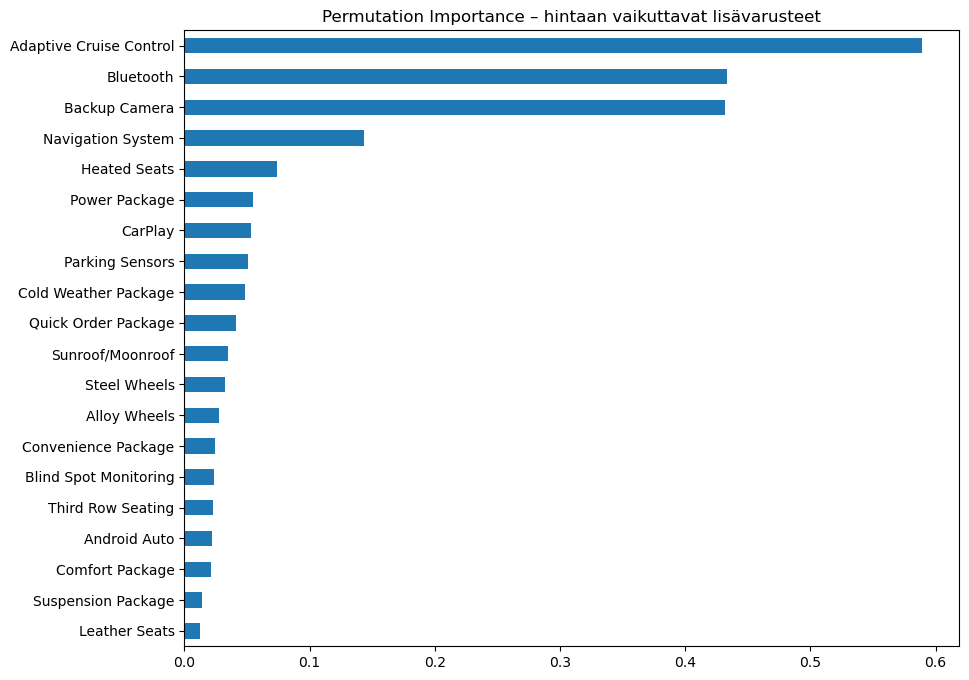

In [36]:
#Tämä ottaa ikuisuuden mun koneella koko aineistolla, eikä edes ole kielimallin mukaan järkevä
#Kielimalli ehdottaa että varusteiden määrä olisi parempi
#Tai määritellään premium varusteet

#Jos haluaa testailla niin pikkuotoksella

df = df.head(1000)


#Mitkä lisävarusteet vaikuttavat (positiivisesti tai negatiivisesti) myyntihintaan, tällä siis
#voidaan arvoida mitä varusteita otetaan mukaan dataframeen. Lisäksi kannattanee karsia
#varusteet joita
#vain harvoissa autoissa, esimerkiksi jos ominaisuuksia on alle 1500 autossa 3 M autosta
#eli 0,05 %:ssa autoissa on ko. varuste
from ast import literal_eval

from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance

import matplotlib.pyplot as plt


#Joissakin riveissä major_options voi olla NaN
df['major_options'] = df['major_options'].fillna("[]")

#Muutetaan string-lista oikeaksi Python-listaksi, eli solussa olevat pilkulla erotetut
#stringit listaksi dataframen sarakkeeseen
df['major_options'] = df['major_options'].apply(lambda x: literal_eval(x) if isinstance(x, str) else x)


#Muunnetaan solussa nyt listana olevat varusteet kukin omaksi sarakkeeksi
#Jos rivillä on ko. varuste, sarakkeeeseen tulee arvoksi 1, jos ei niin 0
mlb = MultiLabelBinarizer()
options_encoded = pd.DataFrame(
    mlb.fit_transform(df['major_options']),
    columns=mlb.classes_,
    index=df.index
)

#Lisätään uudet one-hot-sarakkeet dataframeen
df_onehot = options_encoded

print("One-hot–kolumnit:", df_onehot.columns.tolist())

X = df_onehot
y = df['price']


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

#Voi toki tehdä muillakin regressio malleilla
rf = RandomForestRegressor(
    n_estimators=500,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

#Myyntihinnalle
r = permutation_importance(
    rf, X_test, y_test,
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)


importances = pd.Series(r.importances_mean, index=X.columns)
importances = importances.sort_values(ascending=False)

print("\nTärkeimmät lisävarusteet (top 40):")
print(importances.head(40))



plt.figure(figsize=(10, 8))
importances.head(20).plot(kind='barh')
plt.title("Permutation Importance – hintaan vaikuttavat lisävarusteet")
plt.gca().invert_yaxis()  # korkeimmat ylös
plt.show()

In [37]:
#Varusteiden vaikutus myyntiaikaan

W = df_onehot
z = df['daysonmarket']

#Myyntiajalle
W_train, W_test, z_train, z_test = train_test_split(
    W, z, test_size=0.2, random_state=42
)

rf_time = RandomForestRegressor(
    n_estimators=500,
    random_state=42,
    n_jobs=-1
)

rf_time.fit(W_train, z_train)

#Myyntiajalle
r2 = permutation_importance(
    rf_time, W_test, z_test,
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)


Myyntiaikaan vaikuttavat lisävarusteet (top 20):
Heated Seats                             0.2915
Backup Camera                            0.2164
Quick Order Package                      0.2132
CarPlay                                  0.1827
Adaptive Cruise Control                  0.1765
Alloy Wheels                             0.1393
Leather Seats                            0.1088
Sunroof/Moonroof                         0.1025
Bluetooth                                0.0657
Steel Wheels                             0.0290
Remote Start                             0.0211
Parking Sensors                          0.0187
Third Row Seating                        0.0096
Premium Wheels                           0.0072
Cold Weather Package                     0.0034
M Sport Package                          0.0024
Power Package                            0.0020
RS Package                               0.0018
Luxury Package                           0.0011
Heat Package                          

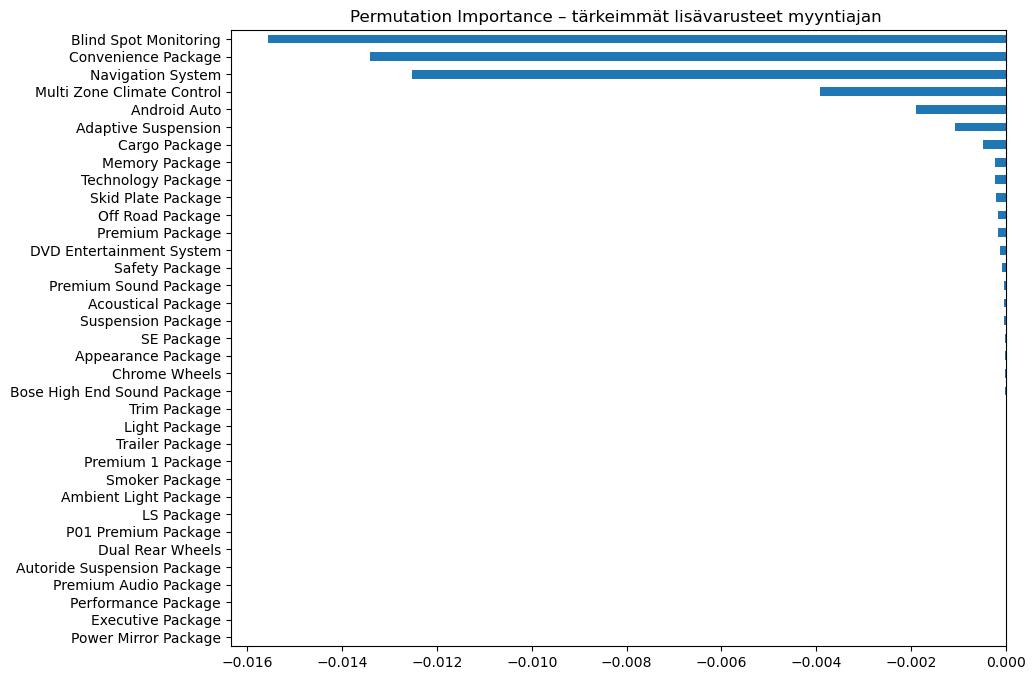

In [38]:

importances = pd.Series(r2.importances_mean, index=W.columns)
importances = importances.sort_values(ascending=False)

#Mitkä varusteet vaikuttavat myyntiaikaan
pd.set_option('display.float_format', '{:.4f}'.format)
print("\nMyyntiaikaan vaikuttavat lisävarusteet (top 20):")
print(importances.head(40))

#Mitkä varusteet nopeuttavat myyntiaikaa
speed_up = importances[importances < 0].sort_values()


print("\nNopeuttavat myyntiä:")
print(speed_up.head(40))


plt.figure(figsize=(10, 8))
speed_up.head(40).plot(kind='barh')
plt.title("Permutation Importance – tärkeimmät lisävarusteet myyntiajan ")
plt.gca().invert_yaxis()  # korkeimmat ylös
plt.show()